# Data Loading

In [1]:
import pandas as pd

# Karena hanya ada satu dataset (layoffs.csv), kita memuatnya sebagai data train
# Jika Anda memiliki data test terpisah, Anda bisa memuatnya dengan pd.read_csv("test.csv")
train = pd.read_csv("layoffs.csv")
train.head()

,company,location,total_laid_off,date,percentage_laid_off,industry,source,stage,funds_raised,country,date_added
0,Blaize,SF Bay Area,NaN,9/30/2026,0.260,AI,https://www.tradingview.com/news/seekingalpha:...,Post-IPO,307.0,United States,10/1/2026
1,Workday,SF Bay Area,525.0,9/29/2026,0.025,HR,https://seekingalpha.com/news/4648205-workday-...,Post-IPO,230.0,United States,10/1/2026
2,Thinkific,"Vancouver, Non-U.S.",96.0,9/23/2026,NaN,Education,https://investors.thinkific.com/2026-09-23-Thi...,Post-IPO,22.0,Canada,9/24/2026
3,Intel,Sacramento,52.0,9/23/2026,NaN,Hardware,https://www.kron4.com/news/technology-ai/intel...,Post-IPO,12.0,United States,9/23/2026
4,Microsoft,Seattle,500.0,9/22/2026,NaN,Other,https://www.businessinsider.com/microsoft-star...,Post-IPO,1.0,United States,9/23/2026


# Data Cleaning dan Transformation

In [2]:
# Menampilkan ringkasan informasi dari dataset
train.info()

# Menampilkan statistik deskriptif dari dataset
train.describe(include="all")

# Memeriksa jumlah nilai yang hilang di setiap kolom
missing_values = train.isnull().sum()
print(missing_values[missing_values > 0])

# Disetel ke 2000 agar kolom penting seperti total_laid_off (1600+ missing) tidak terhapus
less = missing_values[missing_values < 2000].index
over = missing_values[missing_values >= 2000].index

# Contoh mengisi nilai yang hilang dengan median untuk kolom numerik
numeric_features = train[less].select_dtypes(include=['number']).columns
train[numeric_features] = train[numeric_features].fillna(train[numeric_features].median())

# Contoh mengisi nilai yang hilang dengan mode untuk kolom kategori
kategorical_features = train[less].select_dtypes(include=['object']).columns

for column in kategorical_features:
    train[column] = train[column].fillna(train[column].mode()[0])

# Menghapus kolom dengan terlalu banyak nilai yang hilang
df = train.drop(columns=over)

missing_values_df = df.isnull().sum()
print(missing_values_df[missing_values_df > 0])

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4618 entries, 0 to 4617
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   company              4618 non-null   object 
 1   location             4617 non-null   object 
 2   total_laid_off       3016 non-null   float64
 3   date                 4618 non-null   object 
 4   percentage_laid_off  2890 non-null   float64
 5   industry             4616 non-null   object 
 6   source               4615 non-null   object 
 7   stage                4610 non-null   object 
 8   funds_raised         4068 non-null   float64
 9   country              4616 non-null   object 
 10  date_added           4618 non-null   object 
dtypes: float64(3), object(8)
memory usage: 397.0+ KB
location                  1
total_laid_off         1602
percentage_laid_off    1728
industry                  2
source                    3
stage                     8
funds_raised         

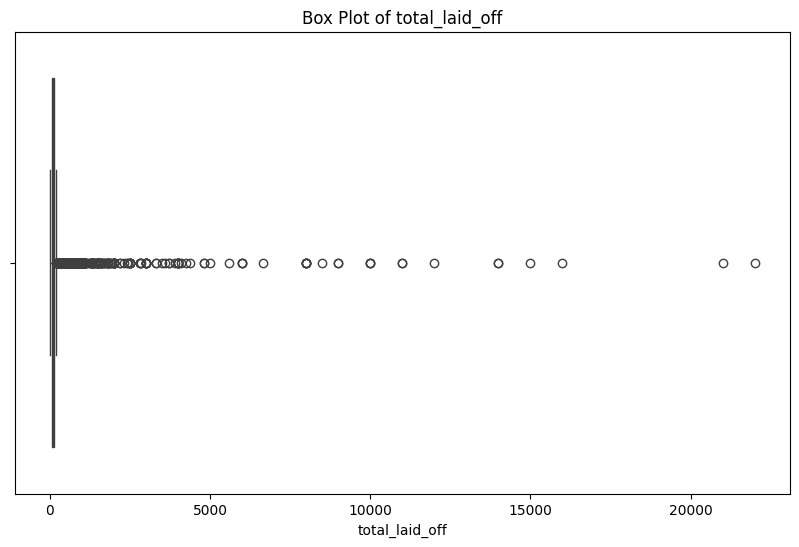

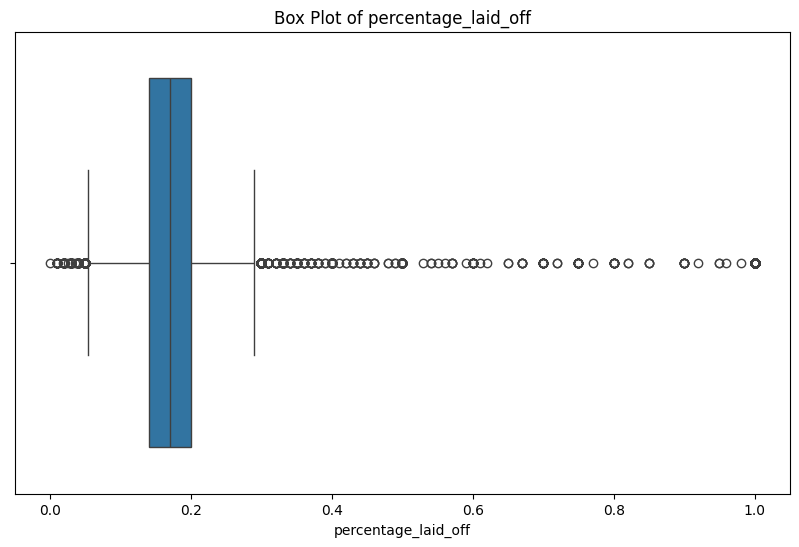

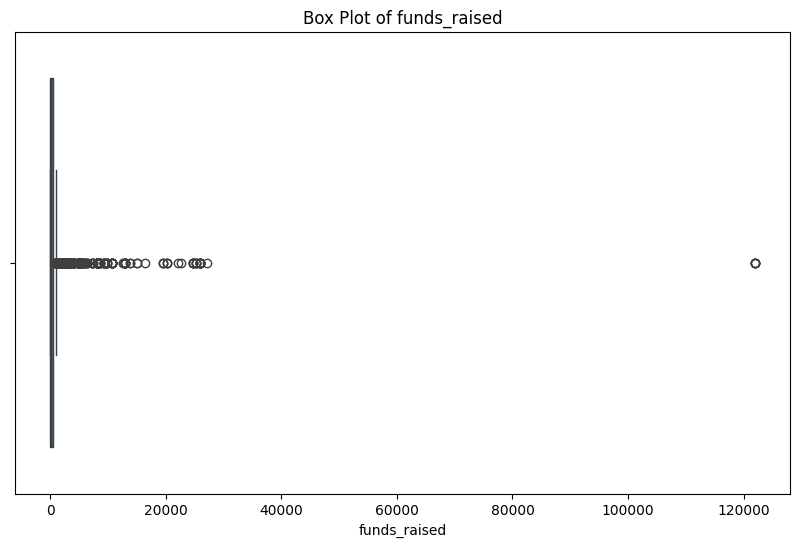

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt

for feature in numeric_features:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=df[feature])
    plt.title(f'Box Plot of {feature}')
    plt.show()

In [4]:
# Contoh sederhana untuk mengidentifikasi outliers menggunakan IQR
Q1 = df[numeric_features].quantile(0.25)
Q3 = df[numeric_features].quantile(0.75)
IQR = Q3 - Q1

# Filter dataframe untuk hanya menyimpan baris yang tidak mengandung outliers pada kolom numerik
condition = ~((df[numeric_features] < (Q1 - 1.5 * IQR)) | (df[numeric_features] > (Q3 + 1.5 * IQR))).any(axis=1)
df_filtered_numeric = df.loc[condition, numeric_features]

# Menggabungkan kembali dengan kolom kategorikal
categorical_features = df.select_dtypes(include=['object']).columns
df = pd.concat([df_filtered_numeric, df.loc[condition, categorical_features]], axis=1)

In [5]:
# Menangani outlier pada kolom 'total_laid_off' dengan median
Q1_val = Q1['total_laid_off']
Q3_val = Q3['total_laid_off']
IQR_val = IQR['total_laid_off']
median = df['total_laid_off'].median()

df['total_laid_off'] = df['total_laid_off'].apply(lambda x: median if x < (Q1_val - 1.5 * IQR_val) or x > (Q3_val + 1.5 * IQR_val) else x)

In [6]:
# Mengganti outlier dengan nilai batas terdekat pada kolom 'total_laid_off'
lower_bound = Q1_val - 1.5 * IQR_val
upper_bound = Q3_val + 1.5 * IQR_val

df['total_laid_off'] = df['total_laid_off'].apply(lambda x: lower_bound if x < lower_bound else upper_bound if x > upper_bound else x)

In [7]:
from sklearn.preprocessing import StandardScaler

# Standardisasi fitur numerik
scaler = StandardScaler()
df[numeric_features] = scaler.fit_transform(df[numeric_features])

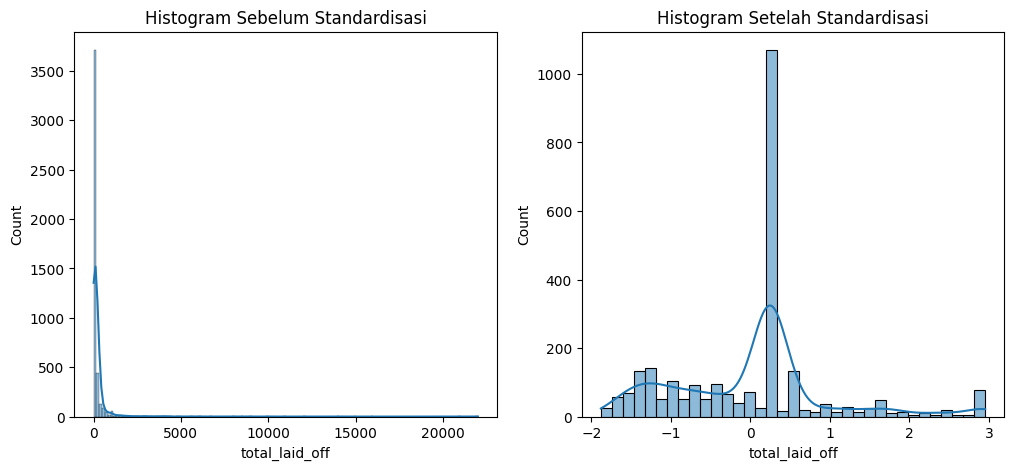

In [8]:
# Histogram Sebelum Standardisasi (Menggunakan kolom numerik pertama, misal 'total_laid_off')
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(train[numeric_features[0]], kde=True)
plt.title("Histogram Sebelum Standardisasi")

# Histogram Setelah Standardisasi
plt.subplot(1, 2, 2)
sns.histplot(df[numeric_features[0]], kde=True)
plt.title("Histogram Setelah Standardisasi")
plt.show()

In [9]:
# Mengidentifikasi baris duplikat
duplicates = df.duplicated()

print("Baris duplikat:")
print(df[duplicates])

# Menghapus baris duplikat
df = df.drop_duplicates()

print("DataFrame setelah menghapus duplikat:")
print(df.head())

Baris duplikat:
Empty DataFrame
Columns: [total_laid_off, percentage_laid_off, funds_raised, company, location, date, industry, source, stage, country, date_added]
Index: []
DataFrame setelah menghapus duplikat:
   total_laid_off  percentage_laid_off  funds_raised    company  \
0        0.243438             2.310714      0.416090     Blaize   
2        0.389973             0.231513     -0.948565  Thinkific   
3       -0.684618             0.231513     -0.996447      Intel   
8        2.929916             0.231513     -0.919835    Trustly   
9       -0.000788             0.231513      2.628269   Bluevine   

              location       date   industry  \
0          SF Bay Area  9/30/2026         AI   
2  Vancouver, Non-U.S.  9/23/2026  Education   
3           Sacramento  9/23/2026   Hardware   
8  Stockholm, Non-U.S.  9/17/2026    Finance   
9  Bengaluru, Non-U.S.  9/17/2026    Finance   

                                              source     stage        country  \
0  https://www.

In [10]:
category_features = df.select_dtypes(include=['object']).columns
print(df[category_features].head())

df_one_hot = pd.get_dummies(df, columns=category_features)
print(df_one_hot.head())

     company             location       date   industry  \
0     Blaize          SF Bay Area  9/30/2026         AI   
2  Thinkific  Vancouver, Non-U.S.  9/23/2026  Education   
3      Intel           Sacramento  9/23/2026   Hardware   
8    Trustly  Stockholm, Non-U.S.  9/17/2026    Finance   
9   Bluevine  Bengaluru, Non-U.S.  9/17/2026    Finance   

                                              source     stage        country  \
0  https://www.tradingview.com/news/seekingalpha:...  Post-IPO  United States   
2  https://investors.thinkific.com/2026-09-23-Thi...  Post-IPO         Canada   
3  https://www.kron4.com/news/technology-ai/intel...  Post-IPO  United States   
8  https://tech.eu/2026/09/17/swedish-fintech-tru...  Acquired         Sweden   
9  https://www.ndtv.com/offbeat/team-of-80-indian...   Unknown          India   

  date_added  
0  10/1/2026  
2  9/24/2026  
3  9/23/2026  
8  9/17/2026  
9  9/17/2026  
   total_laid_off  percentage_laid_off  funds_raised  company_#Paid 

In [11]:
from sklearn.preprocessing import LabelEncoder

# Inisialisasi LabelEncoder
label_encoder = LabelEncoder()
df_lencoder = pd.DataFrame(df)

for col in category_features:
    # Diubah ke string untuk menghindari error tipe data campuran
    df_lencoder[col] = label_encoder.fit_transform(df[col].astype(str)) 

# Menampilkan hasil
print(df_lencoder.head())

   total_laid_off  percentage_laid_off  funds_raised  company  location  date  \
0        0.243438             2.310714      0.416090      216       177   978   
2        0.389973             0.231513     -0.948565     1691       210   960   
3       -0.684618             0.231513     -0.996447      873       178   960   
8        2.929916             0.231513     -0.919835     1746       198   940   
9       -0.000788             0.231513      2.628269      228        16   940   

   industry  source  stage  country  date_added  
0         0    2399      1       56          67  
2         6     423      1        7         855  
3        12    1836      1       56         851  
8         8     659      0       49         835  
9         8    2049     15       24         835  


# EDA & ExDA

In [12]:
df_lencoder.head()

# Menghitung jumlah dan persentase missing values di setiap kolom
missing_values = df_lencoder.isnull().sum()
missing_percentage = (missing_values / len(df_lencoder)) * 100

missing_data = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage': missing_percentage
}).sort_values(by='Missing Values', ascending=False)

# Menampilkan kolom dengan missing values
print(missing_data[missing_data['Missing Values'] > 0])

Empty DataFrame
Columns: [Missing Values, Percentage]
Index: []


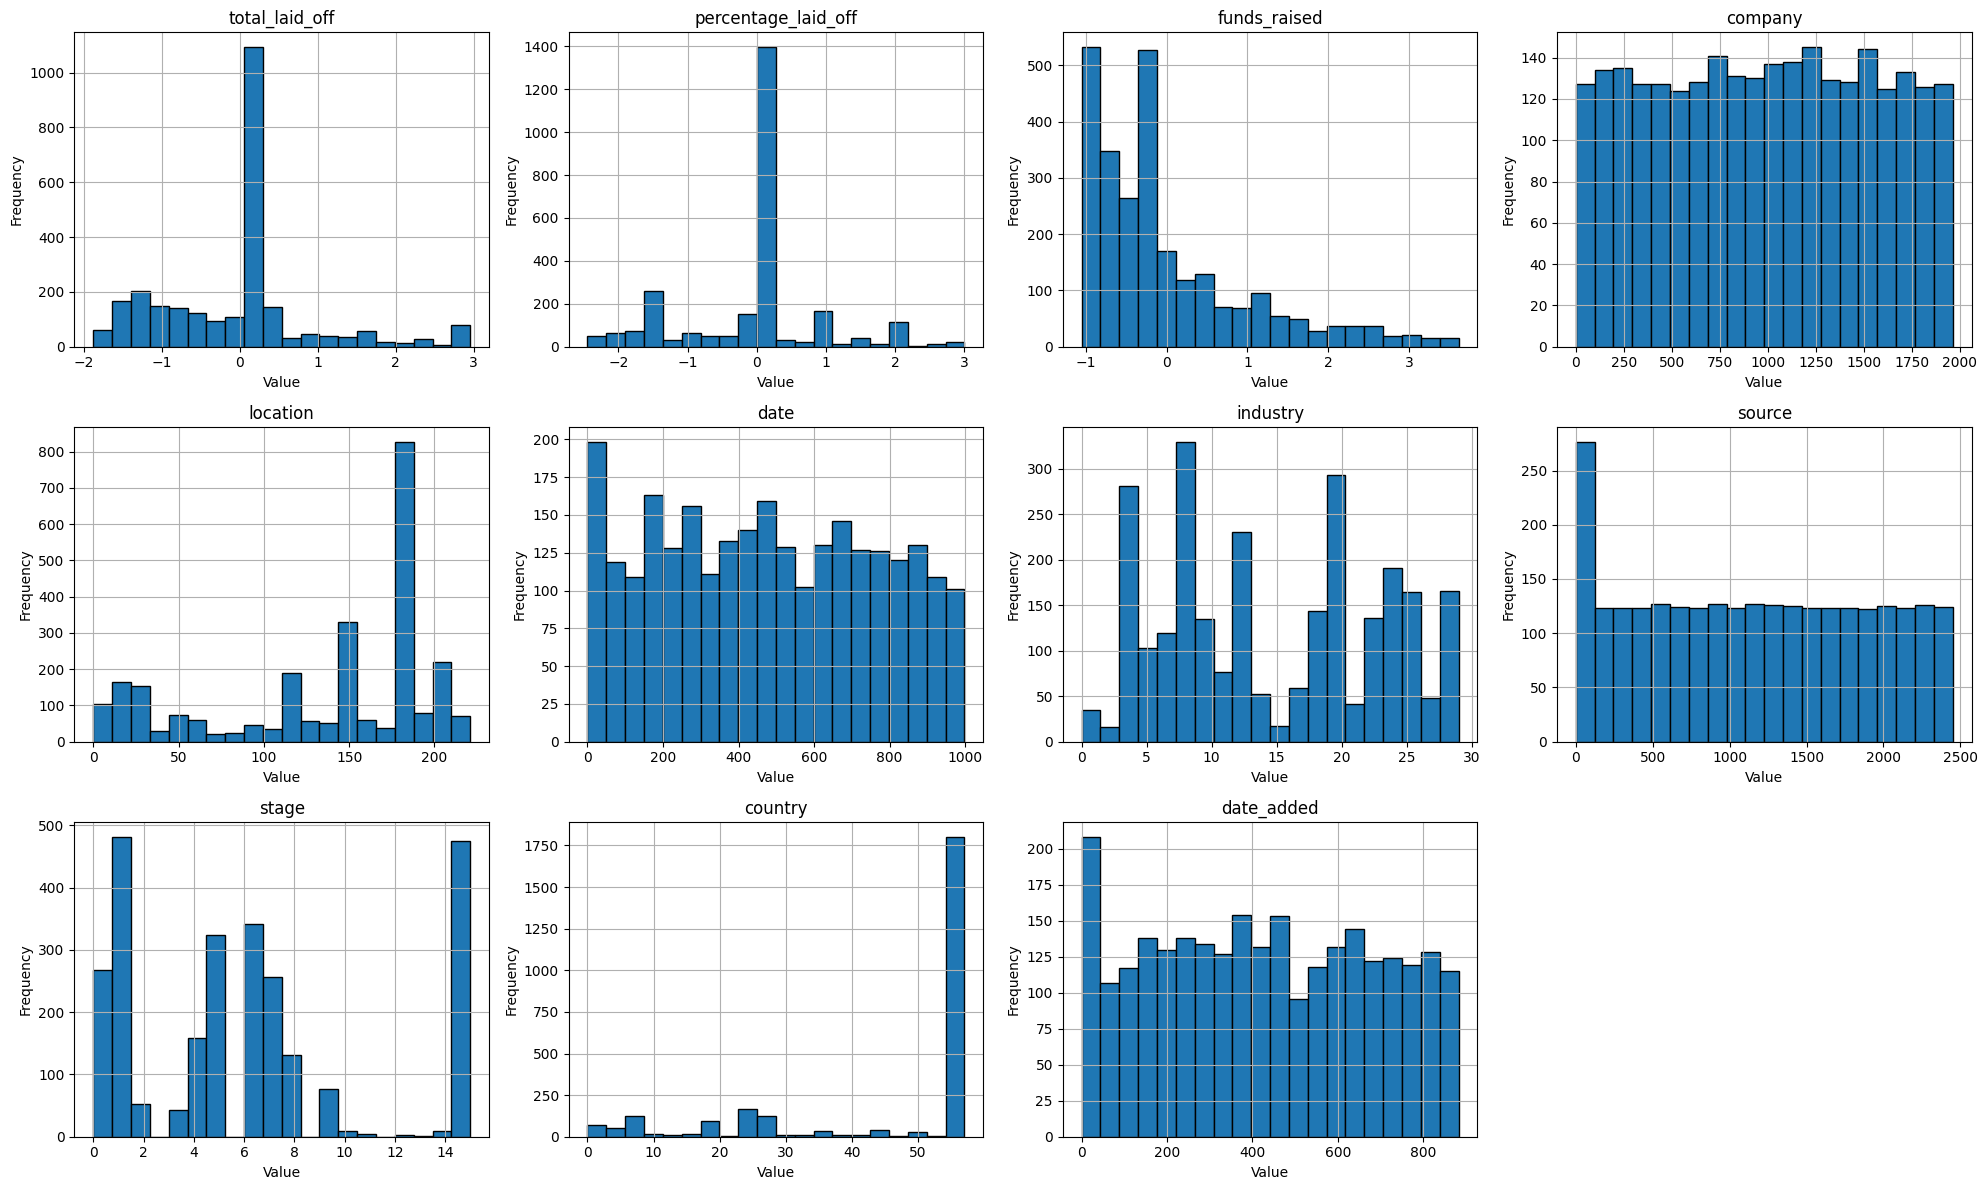

In [13]:
# Menghitung jumlah variabel
num_vars = df_lencoder.shape[1]

# Menentukan jumlah baris dan kolom untuk grid subplot
n_cols = 4  # Jumlah kolom yang diinginkan
n_rows = -(-num_vars // n_cols)  # Ceiling division untuk menentukan jumlah baris

# Membuat subplot
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 4))

# Flatten axes array untuk memudahkan iterasi jika diperlukan
axes = axes.flatten()

# Plot setiap variabel
for i, column in enumerate(df_lencoder.columns):
    df_lencoder[column].hist(ax=axes[i], bins=20, edgecolor='black')
    axes[i].set_title(column)
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Frequency')

# Menghapus subplot yang tidak terpakai (jika ada)
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# Menyesuaikan layout agar lebih rapi
plt.tight_layout()
plt.show()

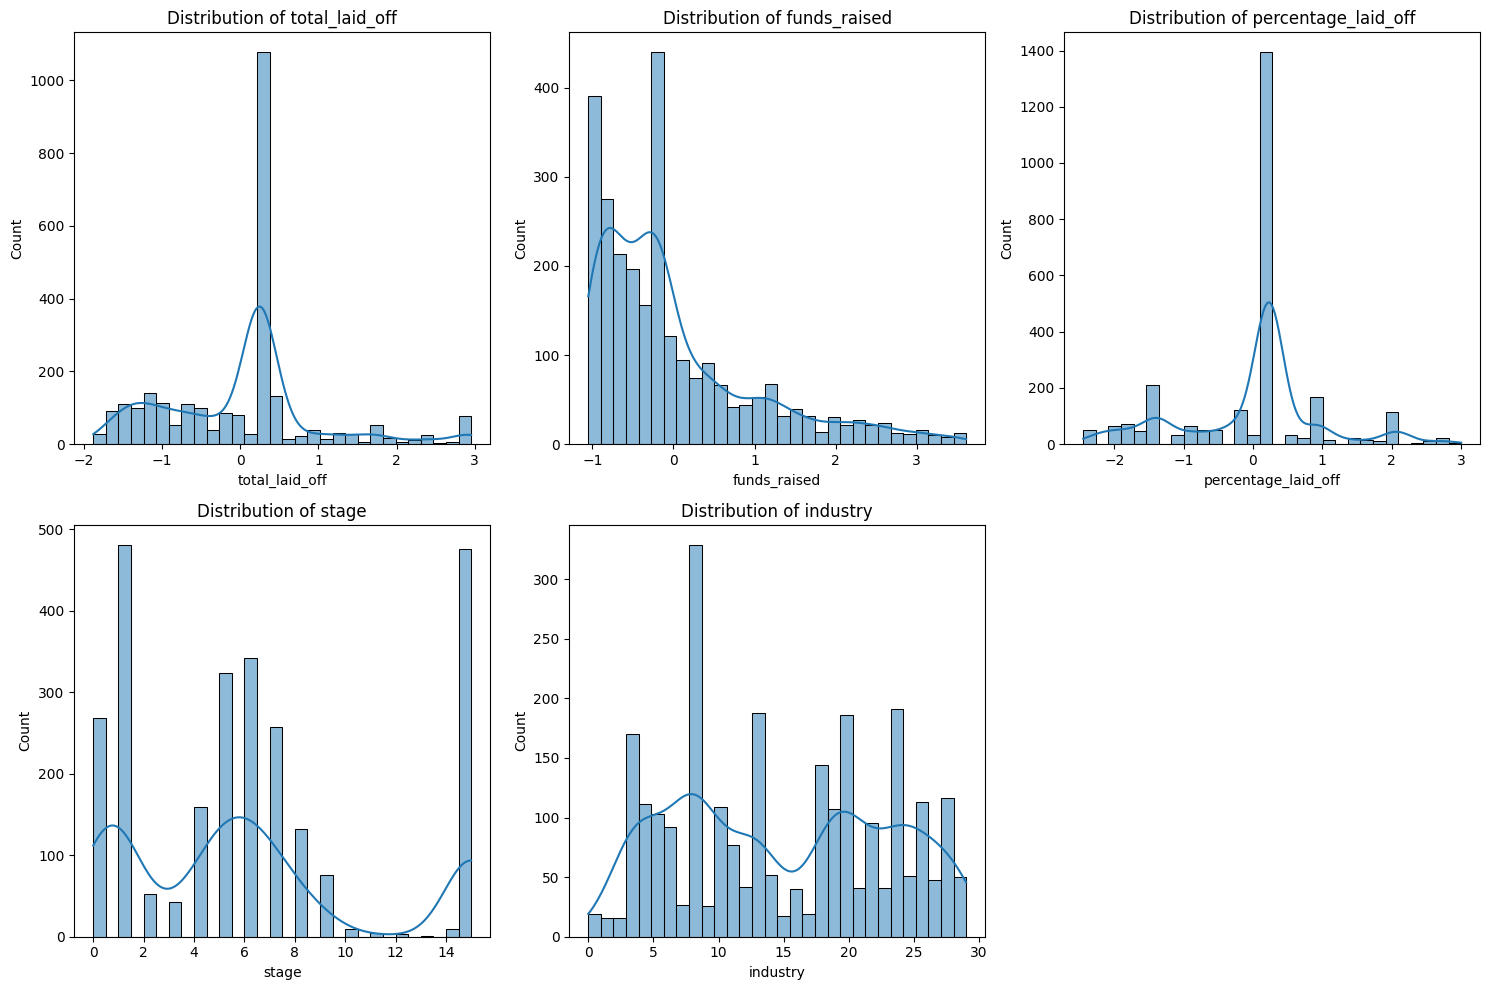

In [14]:
# Visualisasi distribusi data untuk beberapa kolom yang relevan dari layoffs.csv
columns_to_plot = ['total_laid_off', 'funds_raised', 'percentage_laid_off', 'stage', 'industry']

plt.figure(figsize=(15, 10))
for i, column in enumerate(columns_to_plot, 1):
    plt.subplot(2, 3, i)
    sns.histplot(df_lencoder[column], kde=True, bins=30)
    plt.title(f'Distribution of {column}')

plt.tight_layout()
plt.show()

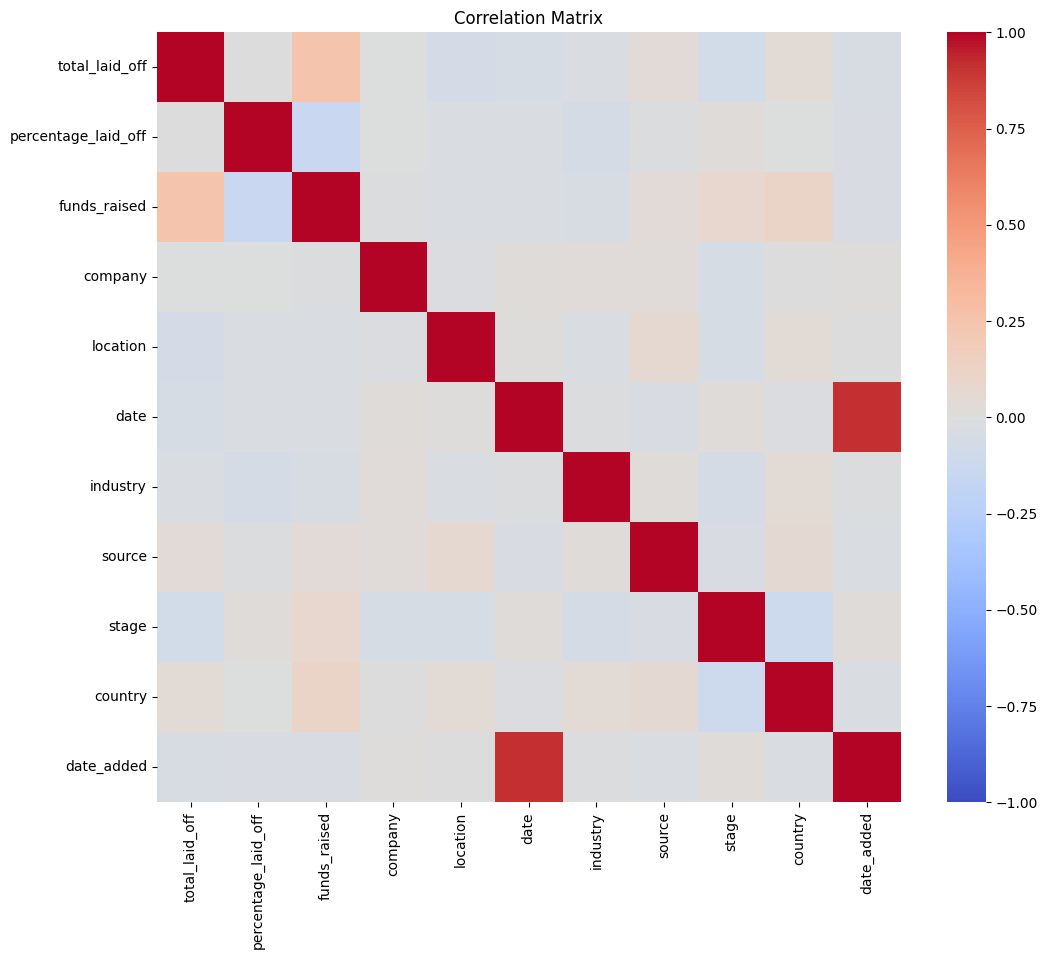

In [15]:
# Visualisasi korelasi antar variabel numerik
plt.figure(figsize=(12, 10))
correlation_matrix = df_lencoder.corr()

sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix')
plt.show()

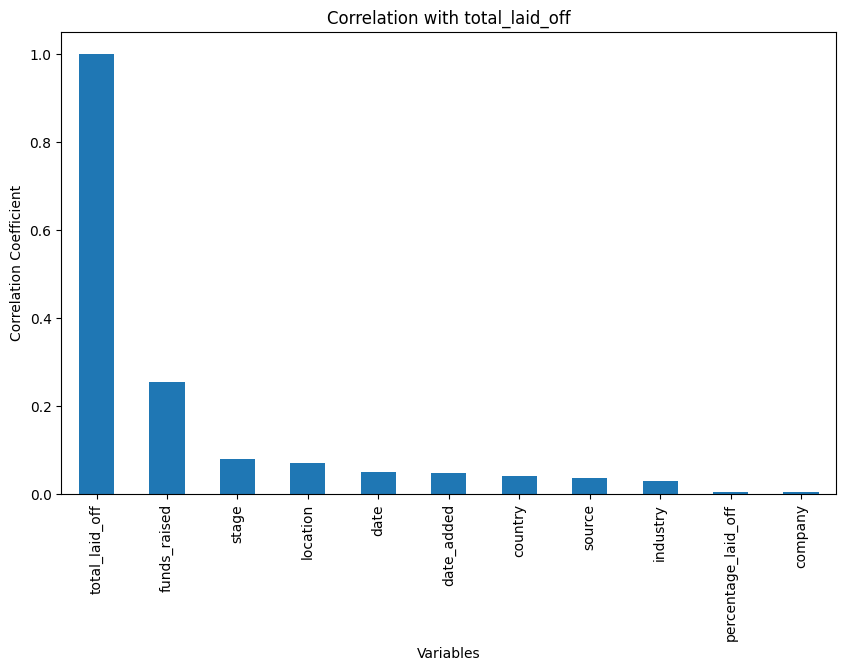

In [16]:
# Menghitung korelasi antara variabel target (total_laid_off) dan semua variabel lainnya
target_corr = df_lencoder.corr()['total_laid_off']

# (Opsional) Mengurutkan hasil korelasi berdasarkan korelasi
target_corr_sorted = target_corr.abs().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
target_corr_sorted.plot(kind='bar')
plt.title('Correlation with total_laid_off')
plt.xlabel('Variables')
plt.ylabel('Correlation Coefficient')
plt.show()

# Data Splitting

In [17]:
import sklearn

# Memisahkan fitur (X) dan target (y). Dalam kasus ini 'total_laid_off' adalah targetnya.
# Pastikan nilai target tidak memiliki missing values setelah diproses.
X = df_lencoder.drop(columns=['total_laid_off']) 
y = df_lencoder['total_laid_off']

In [18]:
from sklearn.model_selection import train_test_split

# Membagi dataset menjadi training dan testing 
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

In [19]:
# Menghitung panjang/jumlah data 
print("Jumlah data: ", len(X))
# Menghitung panjang/jumlah data pada x_train
print("Jumlah data latih: ", len(x_train))
# Menghitung panjang/jumlah data pada x_test
print("Jumlah data test: ", len(x_test))

Jumlah data:  2636
Jumlah data latih:  2108
Jumlah data test:  528


# Cross Validation

In [20]:
#  CROSS VALIDATION 
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestRegressor 

# Kita gunakan algoritma RandomForestRegressor sebagai contoh model prediksi
model = RandomForestRegressor(random_state=1)

# Melakukan k-fold cross validation (misal 5 folds)
# Menggunakan 'neg_mean_squared_error' sebagai metrik evaluasi
cv_scores = cross_val_score(model, X, y, cv=5, scoring='neg_mean_squared_error')

print("Skor Cross Validation (Negative MSE setiap lipatan/fold):", cv_scores)
print("Rata-rata Skor Cross Validation:", cv_scores.mean())

Skor Cross Validation (Negative MSE setiap lipatan/fold): [-1.1636132  -0.80247862 -0.84319286 -0.89114964 -1.03393623]
Rata-rata Skor Cross Validation: -0.9468741094484739
